In [1]:
import pandas as pd
import numpy as np


# Preprocessing
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split

# Models
from sklearn.ensemble import RandomForestClassifier

In [2]:
# Evaluation Metrics
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
)

# **Task 1: Load Dataset**

In [3]:


# Load the dataset
df = pd.read_csv('/content/GermanCredit.csv')

# Identify categorical columns and encode them
label_encoders = {}
for column in df.select_dtypes(include=['object']).columns:
    le = LabelEncoder()
    df[column] = le.fit_transform(df[column].astype(str))
    label_encoders[column] = le

# Assuming the target column is the last column, or 'Class' / 'target'
# Let's inspect columns or assume standard target location (often 'Class' or the last column in German Credit)
target_col = 'Class' if 'Class' in df.columns else df.columns[-1]

X = df.drop(columns=[target_col])
y = df[target_col]

# Stratified split 80:20
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

print(f"Data split successfully!")
print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

Data split successfully!
Training set shape: (800, 20)
Testing set shape: (200, 20)


# **Task 2: Train a Random Forest classifier**

In [6]:
# Initialize the Random Forest Classifier with specified parameters
rf = RandomForestClassifier(n_estimators=200, max_depth=8, random_state=42)

# Train the model
rf.fit(X_train, y_train)

# Make predictions on test set
y_pred = rf.predict(X_test)
y_pred_proba = rf.predict_proba(X_test)[:, 1]

# Calculate metrics
accuracy = accuracy_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_pred_proba)

print(f"Model: {rf}")
print(f"Test Accuracy: {accuracy:.4f}")
print(f"Test ROC-AUC:  {roc_auc:.4f}")

Model: RandomForestClassifier(max_depth=8, n_estimators=200, random_state=42)
Test Accuracy: 0.7600
Test ROC-AUC:  0.7862


# **Task 3: Feature importance & SHAP summary**

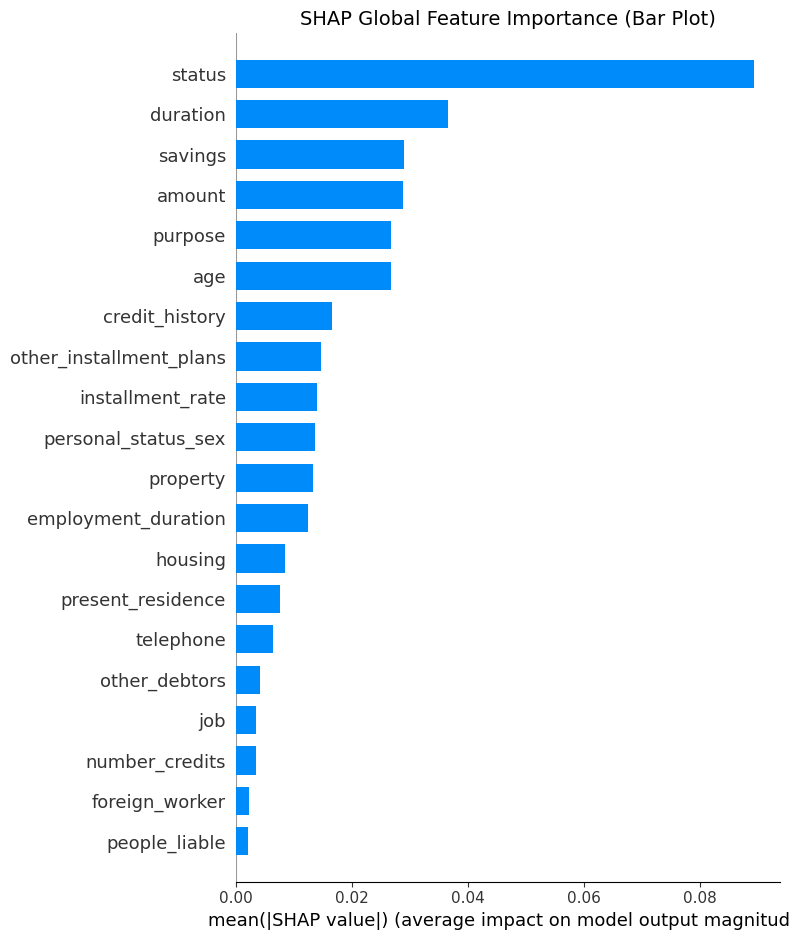

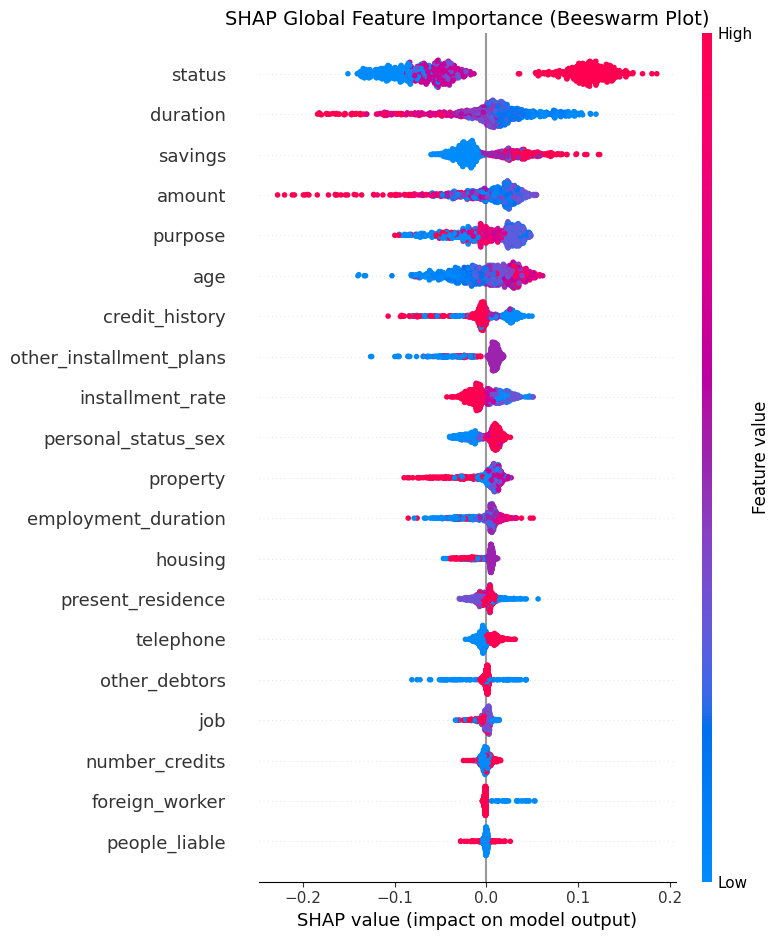


Top 5 Features according to SHAP:
 feature  mean_abs_shap
  status       0.089353
duration       0.036537
 savings       0.028986
  amount       0.028887
 purpose       0.026723


In [7]:
!pip install -q shap
import shap
import matplotlib.pyplot as plt

# Initialize Javascript visualization for SHAP if needed
shap.initjs()

# Instantiate the TreeExplainer
explainer = shap.TreeExplainer(rf)

# Compute SHAP values for X_train
# For binary classification with RandomForest, shap_values might be a list containing values for each class.
# We will use the SHAP values corresponding to the positive class (usually index 1).
shap_values = explainer.shap_values(X_train)

# Extract correct shap values format depending on SHAP library version
if isinstance(shap_values, list):
    # For older SHAP versions
    shap_values_class1 = shap_values[1]
elif len(shap_values.shape) == 3:
    # For newer SHAP versions where shape is (samples, features, classes)
    shap_values_class1 = shap_values[:, :, 1]
else:
    shap_values_class1 = shap_values

# Plot the SHAP summary beeswarm plot
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values_class1, X_train, plot_type="bar", show=False)
plt.title("SHAP Global Feature Importance (Bar Plot)", fontsize=14)
plt.tight_layout()
plt.show()

# Plot beeswarm for deeper insights
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values_class1, X_train, show=False)
plt.title("SHAP Global Feature Importance (Beeswarm Plot)", fontsize=14)
plt.tight_layout()
plt.show()

# Calculate top 5 features based on mean absolute SHAP values
mean_abs_shap = np.mean(np.abs(shap_values_class1), axis=0)
importance_df = pd.DataFrame({
    'feature': X_train.columns,
    'mean_abs_shap': mean_abs_shap
}).sort_values(by='mean_abs_shap', ascending=False)

print("\nTop 5 Features according to SHAP:")
print(importance_df.head(5).to_string(index=False))

# **Task 4: SHAP waterfall/force plot**

Selected applicant at index 1 of the test set (original index: 735).
Predicted Probability of being 'Good' (Class 1): 0.4490


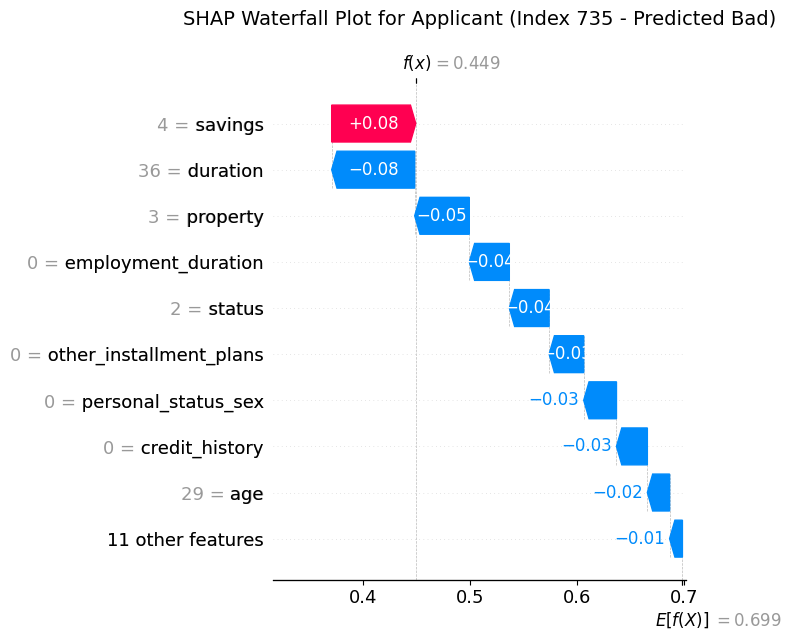


Top 3 contributing reasons for this prediction:
1. savings = 4 (increased probability of being classified 'Good' by 0.0787)
2. duration = 36 (decreased probability of being classified 'Good' by 0.0777)
3. property = 3 (decreased probability of being classified 'Good' by 0.0511)


In [8]:

# Find indices in the test set where prediction is 0 (bad/rejected)
# y_pred corresponds to predictions on X_test
bad_indices_in_test = np.where(y_pred == 0)[0]

if len(bad_indices_in_test) == 0:
    print("No applicant predicted as 'bad' found in the test set.")
else:
    # Select the first applicant predicted as 'bad'
    selected_test_idx = bad_indices_in_test[0]
    applicant_data = X_test.iloc[[selected_test_idx]]

    # Calculate local SHAP values for this applicant using the existing explainer
    # explainer = shap.TreeExplainer(rf)
    # Get SHAP values for this individual
    sh_val_individual = explainer(applicant_data)

    # For binary classification with RandomForest, SHAP values shape may have a 3rd dimension [samples, features, classes]
    # Extract SHAP values corresponding to the positive class (class 1, credit_risk=1/good)
    # Since they are predicted 'bad', we can see why their probability of being 'good' is pushed down
    if len(sh_val_individual.values.shape) == 3:
        # standard shap.Explanation format: [samples, features, classes]
        sh_val_individual_class1 = sh_val_individual[:, :, 1]
    else:
        sh_val_individual_class1 = sh_val_individual

    print(f"Selected applicant at index {selected_test_idx} of the test set (original index: {X_test.index[selected_test_idx]}).")
    print(f"Predicted Probability of being 'Good' (Class 1): {y_pred_proba[selected_test_idx]:.4f}")

    # Generate Waterfall Plot
    plt.figure(figsize=(10, 6))
    shap.plots.waterfall(sh_val_individual_class1[0], max_display=10, show=False)
    plt.title(f"SHAP Waterfall Plot for Applicant (Index {X_test.index[selected_test_idx]} - Predicted Bad)", fontsize=14, pad=20)
    plt.tight_layout()
    plt.show()

    # Extract top 3 features with the highest absolute contribution
    individual_shap_values = sh_val_individual_class1.values[0]
    feature_names = X_test.columns

    reasons_df = pd.DataFrame({
        'Feature': feature_names,
        'Value': applicant_data.values[0],
        'SHAP Value': individual_shap_values,
        'Absolute Impact': np.abs(individual_shap_values)
    }).sort_values(by='Absolute Impact', ascending=False)

    print("\nTop 3 contributing reasons for this prediction:")
    for i, row in enumerate(reasons_df.head(3).itertuples(), 1):
        direction = "decreased" if row._3 < 0 else "increased"
        print(f"{i}. {row.Feature} = {row.Value} ({direction} probability of being classified 'Good' by {abs(row._3):.4f})")

# **Task 5: Compare the LIME and SHAP**

In [9]:
!pip install -q lime
from lime.lime_tabular import LimeTabularExplainer

# Identify categorical columns to supply to LIME Explainer
categorical_features = [X_train.columns.get_loc(col) for col in label_encoders.keys()]
categorical_names = {}
for col in label_encoders.keys():
    col_idx = X_train.columns.get_loc(col)
    categorical_names[col_idx] = list(label_encoders[col].classes_)

# Initialize LIME Tabular Explainer
explainer_lime = LimeTabularExplainer(
    training_data=np.array(X_train),
    feature_names=X_train.columns,
    class_names=['Bad', 'Good'],
    categorical_features=categorical_features,
    categorical_names=categorical_names,
    mode='classification',
    random_state=42
)

# The same applicant selected previously was at test index 1 (original index 735)
selected_idx = 1
applicant_data_single = X_test.iloc[selected_idx]

# Explain prediction
exp = explainer_lime.explain_instance(
    data_row=applicant_data_single,
    predict_fn=rf.predict_proba,
    num_features=5
)

# Show the visualization/details of explanation
print(f"LIME Explanation for Applicant (Index {X_test.index[selected_idx]}):")
lime_reasons = exp.as_list()
for i, (feature_desc, weight) in enumerate(lime_reasons, 1):
    direction = "decreases" if weight < 0 else "increases"
    print(f"{i}. {feature_desc} (Weight: {weight:.4f} -> {direction} probability of 'Good')")

# Extract top 3 features from LIME
# LIME outputs a description like "savings = 4" or "duration > 30.00"
top_3_lime_features = []
for feature_desc, _ in lime_reasons[:3]:
    # Try to find which column name matches the description
    matched_col = None
    for col in X_test.columns:
        if col in feature_desc:
            matched_col = col
            break
    top_3_lime_features.append(matched_col if matched_col else feature_desc)

top_3_shap_features = ['savings', 'duration', 'property']

print("\n--- Comparison of Top 3 Reasons ---")
print(f"SHAP top 3: {top_3_shap_features}")
print(f"LIME top 3: {top_3_lime_features}")

matches = set(top_3_shap_features).intersection(set(top_3_lime_features))
print(f"Agreement Count: {len(matches)} / 3")
if len(matches) > 0:
    print(f"Common top features: {list(matches)}")
else:
    print("There is no overlap in the top 3 features between SHAP and LIME.")

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


/usr/local/lib/python3.13/dist-packages/lime/discretize.py:110: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  ret[feature] = int(self.lambdas[feature](ret[feature]))
/usr/local/lib/python3.13/dist-packages/lime/discretize.py:110: FutureWarning: Series.__setitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To set a value by position, use `ser.iloc[pos] = value`
  ret[feature] = int(self.lambdas[feature](ret[feature]))
/usr/local/lib/python3.13/dist-packages/lime/lime_tabular.py:544: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.

LIME Explanation for Applicant (Index 735):
1. duration > 24.00 (Weight: -0.1083 -> decreases probability of 'Good')
2. amount > 3870.50 (Weight: -0.0828 -> decreases probability of 'Good')
3. status=0 <= ... < 200 DM (Weight: -0.0620 -> decreases probability of 'Good')
4. property=unknown/no property (Weight: -0.0457 -> decreases probability of 'Good')
5. savings=unknown/no savings account (Weight: 0.0399 -> increases probability of 'Good')

--- Comparison of Top 3 Reasons ---
SHAP top 3: ['savings', 'duration', 'property']
LIME top 3: ['duration', 'amount', 'status']
Agreement Count: 1 / 3
Common top features: ['duration']


# **Task 6: Rejection message**

In [10]:
# Rejection letter draft based on the primary factors
rejection_message = """
Dear Applicant,

Thank you for your interest in applying for credit with our institution. After careful review of your application, we regret to inform you that we are unable to approve your credit request at this time.

Our decision was primarily influenced by the following factors:
1. Loan Duration: The requested repayment period of 36 months presents a higher risk profile.
2. Loan Amount: The requested credit amount (3,990 DM) is exceptionally high relative to typical parameters.
3. Collateral/Property status: The lack of registered real estate or sufficient property security for this application.

We appreciate your understanding and welcome you to apply again in the future if your financial circumstances change.

Sincerely,
Credit Underwriting Department
"""

print("=== Rejection Message ===")
print(rejection_message)

# Identify if any sensitive attributes are in the top reasons
sensitive_attributes = ['age', 'personal_status_sex', 'foreign_worker']
top_negative_reasons = ['duration', 'amount', 'property']

print("=== Fair Lending & Sensitivity Check ===")
found_sensitive = [attr for attr in sensitive_attributes if attr in top_negative_reasons]
if found_sensitive:
    print(f"WARNING: Sensitive attribute(s) {found_sensitive} found in the top negative features!")
else:
    print("Pass: No sensitive attributes (age, personal_status, foreign_worker) were used in the top negative factors for this decision.")

=== Rejection Message ===

Dear Applicant,

Thank you for your interest in applying for credit with our institution. After careful review of your application, we regret to inform you that we are unable to approve your credit request at this time.

Our decision was primarily influenced by the following factors:
1. Loan Duration: The requested repayment period of 36 months presents a higher risk profile.
2. Loan Amount: The requested credit amount (3,990 DM) is exceptionally high relative to typical parameters.
3. Collateral/Property status: The lack of registered real estate or sufficient property security for this application.

We appreciate your understanding and welcome you to apply again in the future if your financial circumstances change.

Sincerely,
Credit Underwriting Department

=== Fair Lending & Sensitivity Check ===
Pass: No sensitive attributes (age, personal_status, foreign_worker) were used in the top negative factors for this decision.
